# Phase 3 — PLRNN State Space Model (PLRNN-SSM)

**Dynamical Systems in Machine Learning · Team 15 · University project**

**Aim.** Implement and assess a *nonlinear generative latent state-space model* on the synthetic Lorenz and van der Pol datasets from Phase 1, comparing with the linear Gaussian LDS baseline in Phase 2.

**Source:** Koppe et al. (2019), *Identifying nonlinear dynamical systems via generative recurrent neural networks with applications to fMRI*, PLOS Computational Biology, https://doi.org/10.1371/journal.pcbi.1007263.

> **Methodological accuracy:** this project uses an independent alternating **MAP approximation**, not the paper's exact Laplace-EM or BOLD observation model. All training uses the first 700 points; held-out samples are reserved for evaluation.

## 1. Mathematical model

The nonlinear latent transition is

$$
z_t=A z_{t-1}+W\operatorname{ReLU}(z_{t-1})+h+\varepsilon_t,\qquad \varepsilon_t\sim\mathcal{N}(0,Q).
$$

The observation equation is

$$
x_t=B\operatorname{ReLU}(z_t)+\eta_t,\qquad\eta_t\sim\mathcal{N}(0,R).
$$

Here $A$ is diagonal, $W$ has zeros on its diagonal, $z_t\in\mathbb{R}^M$ is latent and $x_t\in\mathbb{R}^N$ is observed. We omit external stimulus inputs during the synthetic experiments. Unlike the LDS, this PLRNN can in principle exhibit nonlinear attractor behavior. That potential does **not** guarantee that a given training run learns the ground-truth attractor.

## 2. Approximate MAP training

With parameters fixed, we optimize the entire latent training path $Z$ to reduce a weighted squared-error objective:

$$
\mathcal{L}_{\mathrm{MAP}}(Z;\theta) =
\frac{1}{T R}\sum_{t=1}^{T}\lVert x_t-B\operatorname{ReLU}(z_t)\rVert_2^2
+\frac{1}{(T-1) Q}\sum_{t=2}^{T}\lVert z_t-A z_{t-1}-W\operatorname{ReLU}(z_{t-1})-h\rVert_2^2.
$$

This expression omits normalizing constants and adds a small anchor penalty during optimization; $Q$ and $R$ are scalar variances here. It is **not** the ELBO of exact EM. We alternate Adam optimization over $Z$ with regularized least-squares updates of the model matrices. The process variance schedule $(1,0.3,0.1,0.03)$ makes dynamics more important in successive stages.

For test-time predictions, we use a *separate training-only auxiliary encoder and local recursive MAP correction*, not the paper's posterior E-step.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise FileNotFoundError('Open notebook from the repository root or notebooks/ folder')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
from src.models.plrnn import PiecewiseLinearSSM
from src.evaluation.dynamics import occupancy_metrics
from src.training.run_plrnn import run_experiments

print('Repository:', ROOT)
print('NumPy:', np.__version__)

Repository: C:\PLRNN-Project
NumPy: 2.5.5


## 3. Verify Phase 1 + Phase 2 inputs

Training and evaluation use the existing Phase 1 `.npz` datasets, and the saved LDS parameters and metrics from Phase 2. We **do not regenerate** the data here.

In [2]:
from src.data.preprocessing import load_dataset

for system in ('van_der_pol', 'lorenz'):
    ds = load_dataset(ROOT / 'data' / 'synthetic' / f'{system}_seed42.npz')
    assert (ROOT / 'results' / 'metrics' / f'lds_{system}.json').exists()
    assert (ROOT / 'results' / 'metrics' / f'lds_{system}_model.npz').exists()
    print(f'{system}: total={len(ds["x_obs"])}, train={int(ds["train_end"])}, '
          f'test={len(ds["x_obs"])-int(ds["train_end"])}, observations={ds["x_obs"].shape[1]}')

van_der_pol: total=1000, train=700, test=300, observations=2
lorenz: total=1000, train=700, test=300, observations=3


## 4. Train both PLRNNs and evaluate on the held-out test split

`run_experiments()` trains the two models using the fixed seed 42, writes the `.npz` model files and `.json` metrics, and creates labeled figures. It does **not** modify the saved Phase 2 LDS results. You may also run `python -m src.training.run_plrnn` instead of running this cell.

In [3]:
records = run_experiments(data_dir=ROOT/'data'/'synthetic',
                          figs=ROOT/'results'/'figures',
                          metrics=ROOT/'results'/'metrics',
                          quick=False, seed=42)


VAN_DER_POL: fitting PLRNN-SSM (training 700/1000, M=8)


Stage 1/4: Q=1.0000, observation MSE=0.00008, dynamics MSE=0.00222
Stage 2/4: Q=0.3000, observation MSE=0.00024, dynamics MSE=0.00091
Stage 3/4: Q=0.1000, observation MSE=0.00091, dynamics MSE=0.00057
Stage 4/4: Q=0.0300, observation MSE=0.00273, dynamics MSE=0.00032
Horizon   PLRNN MSE   LDS MSE   Persistence
   1         0.0308     0.0236    0.0273
   5         0.0793     0.1308    0.1966
  10         0.1432     0.3131    0.5714
  20         0.1882     0.4560    1.1532
PLRNN free generation: {'histogram_kl_raw': 3.803442581338042, 'histogram_js': 0.28328113452434567, 'n_reference': 300, 'n_generated': 300, 'histogram_width': 1.0, 'histogram_alpha': 0.001, 'max_abs_generated': 1.6967414939541121}

LORENZ: fitting PLRNN-SSM (training 700/1000, M=12)
Stage 1/4: Q=1.0000, observation MSE=0.00003, dynamics MSE=0.00207
Stage 2/4: Q=0.3000, observation MSE=0.00007, dynamics MSE=0.00092
Stage 3/4: Q=0.1000, observation MSE=0.00051, dynamics MSE=0.00063
Stage 4/4: Q=0.0300, observation MSE=0.

## 5. Compare held-out forecast MSE

The target is a future observed sample $x_{t+h}$. The anchor latent state depends only on data available up to time $t$. The forecast recursively runs without the intermediate observations.

**Caveat:** LDS uses the Kalman filter; our PLRNN uses a learned causal recognition approximation. The model sizes are not equal (LDS: 2/3; PLRNN: 8/12 latent units), so do **not** interpret this single run as a fully controlled superiority claim.


 Van Der Pol
horizon    PLRNN      LDS      Persistence
      1    0.0308    0.0236      0.0273
      5    0.0793    0.1308      0.1966
     10    0.1432    0.3131      0.5714
     20    0.1882    0.4560      1.1532

 Lorenz
horizon    PLRNN      LDS      Persistence
      1    0.0416    0.0590      0.0531
      5    0.2635    0.9315      0.7411
     10    0.8579    2.9486      2.0920
     20    2.9334    5.5368      3.2890


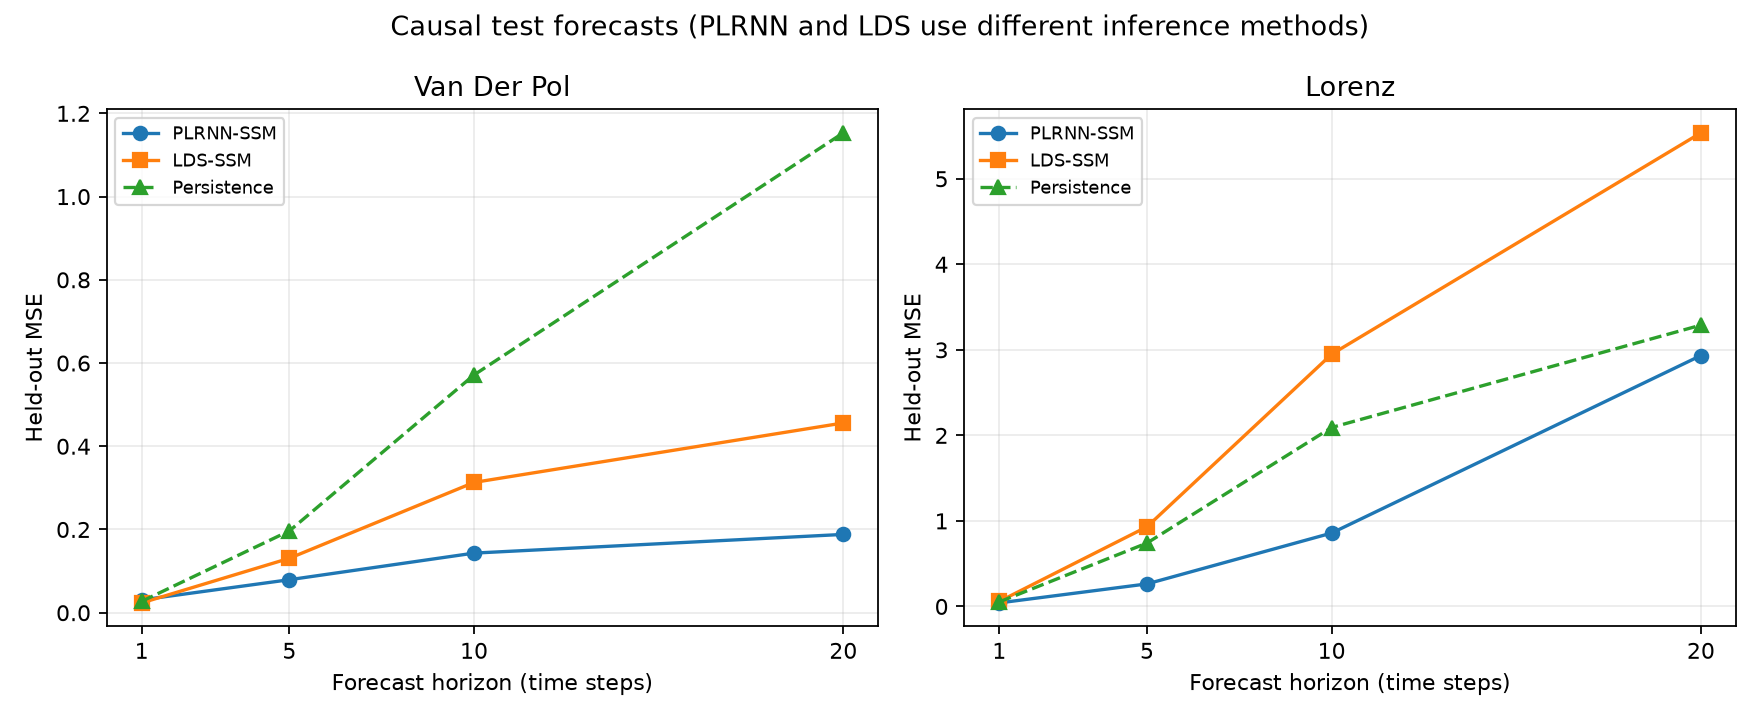

In [4]:
for system, d in records.items():
    print('\n',system.replace('_',' ').title())
    print('horizon    PLRNN      LDS      Persistence')
    for h in (1, 5, 10, 20):
        print(f'{h:>7d}  {d["plrnn_mse"][str(h)]:>8.4f}  '
              f'{d["lds_mse"][str(h)]:>8.4f}  {d["persistence_mse"][str(h)]:>10.4f}')

display(Image(filename=str(ROOT/'results'/'figures'/'plrnn_forecast_comparison.png')))

## 6. Evaluate long-run autonomous dynamics

The key scientific question is whether the fitted PLRNN can generate a **new trajectory**, not whether it matches the exact future samples after a few steps.

We compare the trajectory geometry in a common observation space with the test reference and with the LDS. The histogram divergence is **raw** $D_{\mathrm{KL}}(p_{\mathrm{true}}\|p_{\mathrm{gen}})$, with smoothing and overflow bins. It is *not* the paper's normalized $\widetilde{\mathrm{KL}}_x$. The Jensen–Shannon divergence provides a second, symmetric occupancy measure.

$$
D_{\mathrm{KL}}(p\|q)=\sum_k p_k\log\frac{p_k}{q_k},\qquad \mathrm{JSD}(p,q)=\frac12 D_{\mathrm{KL}}(p\|m)+\frac12 D_{\mathrm{KL}}(q\|m),\quad m=\frac{p+q}{2}.
$$

van_der_pol:
  PLRNN free: {'histogram_kl_raw': 3.803442581338042, 'histogram_js': 0.28328113452434567, 'n_reference': 300, 'n_generated': 300, 'histogram_width': 1.0, 'histogram_alpha': 0.001, 'max_abs_generated': 1.6967414939541121}
  LDS free  : {'histogram_kl_raw': 4.646957279843174, 'histogram_js': 0.3577177397995359, 'n_reference': 300, 'n_generated': 300, 'histogram_width': 1.0, 'histogram_alpha': 0.001}


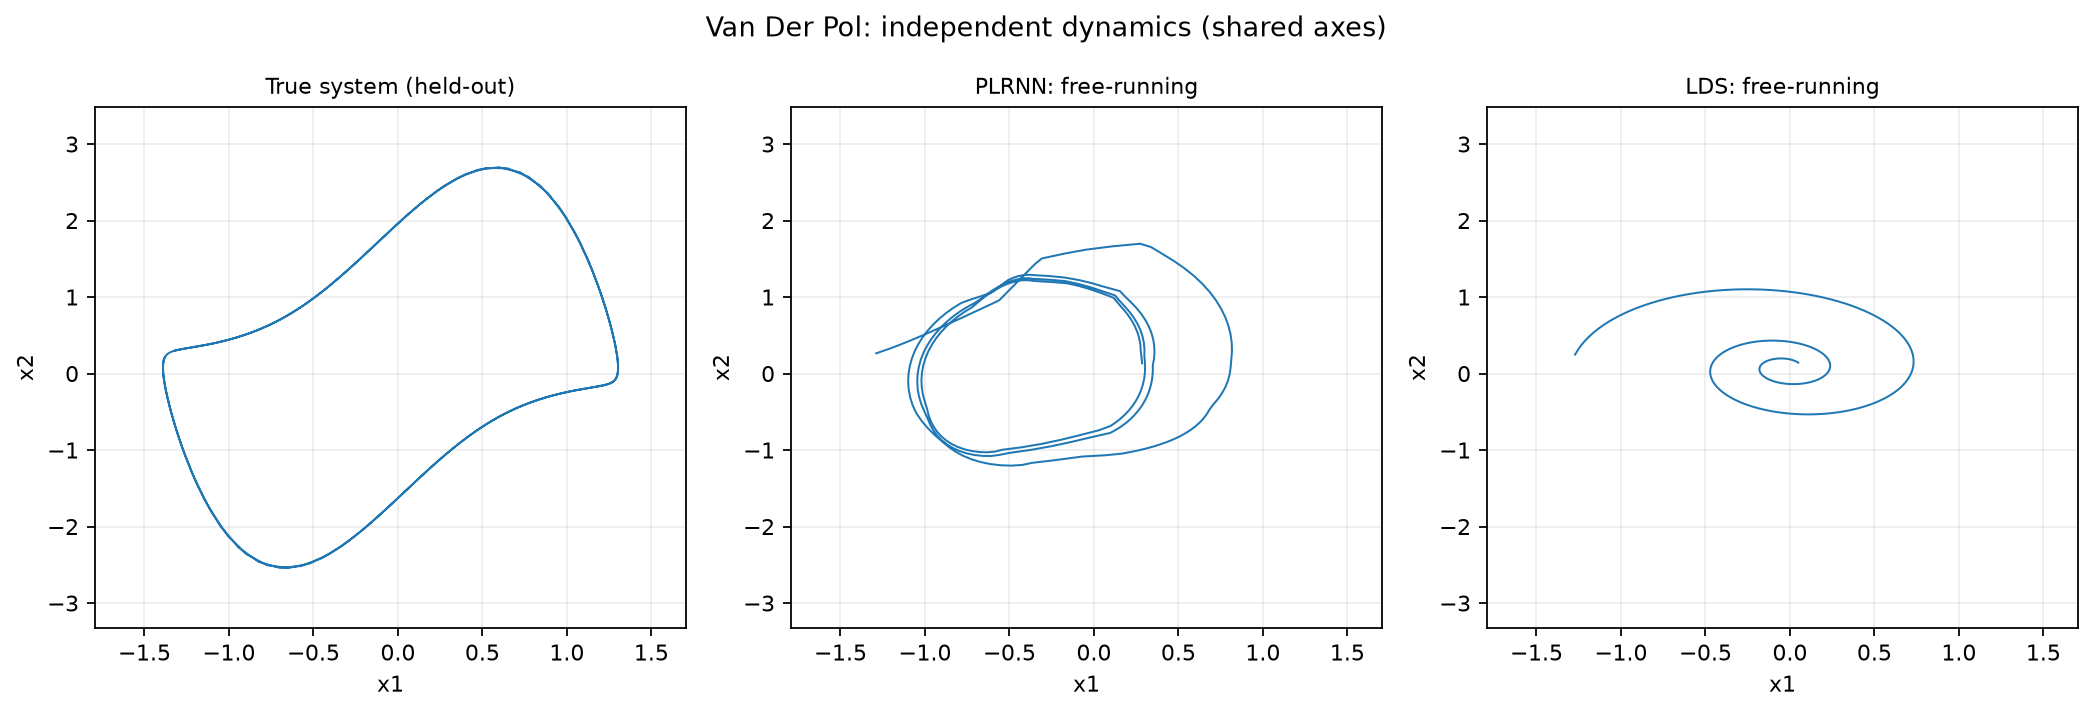

lorenz:
  PLRNN free: {'histogram_kl_raw': 6.807627585436095, 'histogram_js': 0.5715715815427689, 'n_reference': 300, 'n_generated': 300, 'histogram_width': 1.0, 'histogram_alpha': 0.001, 'max_abs_generated': 1.6567348171601766}
  LDS free  : {'histogram_kl_raw': 7.747492962310313, 'histogram_js': 0.640756690374167, 'n_reference': 300, 'n_generated': 300, 'histogram_width': 1.0, 'histogram_alpha': 0.001}


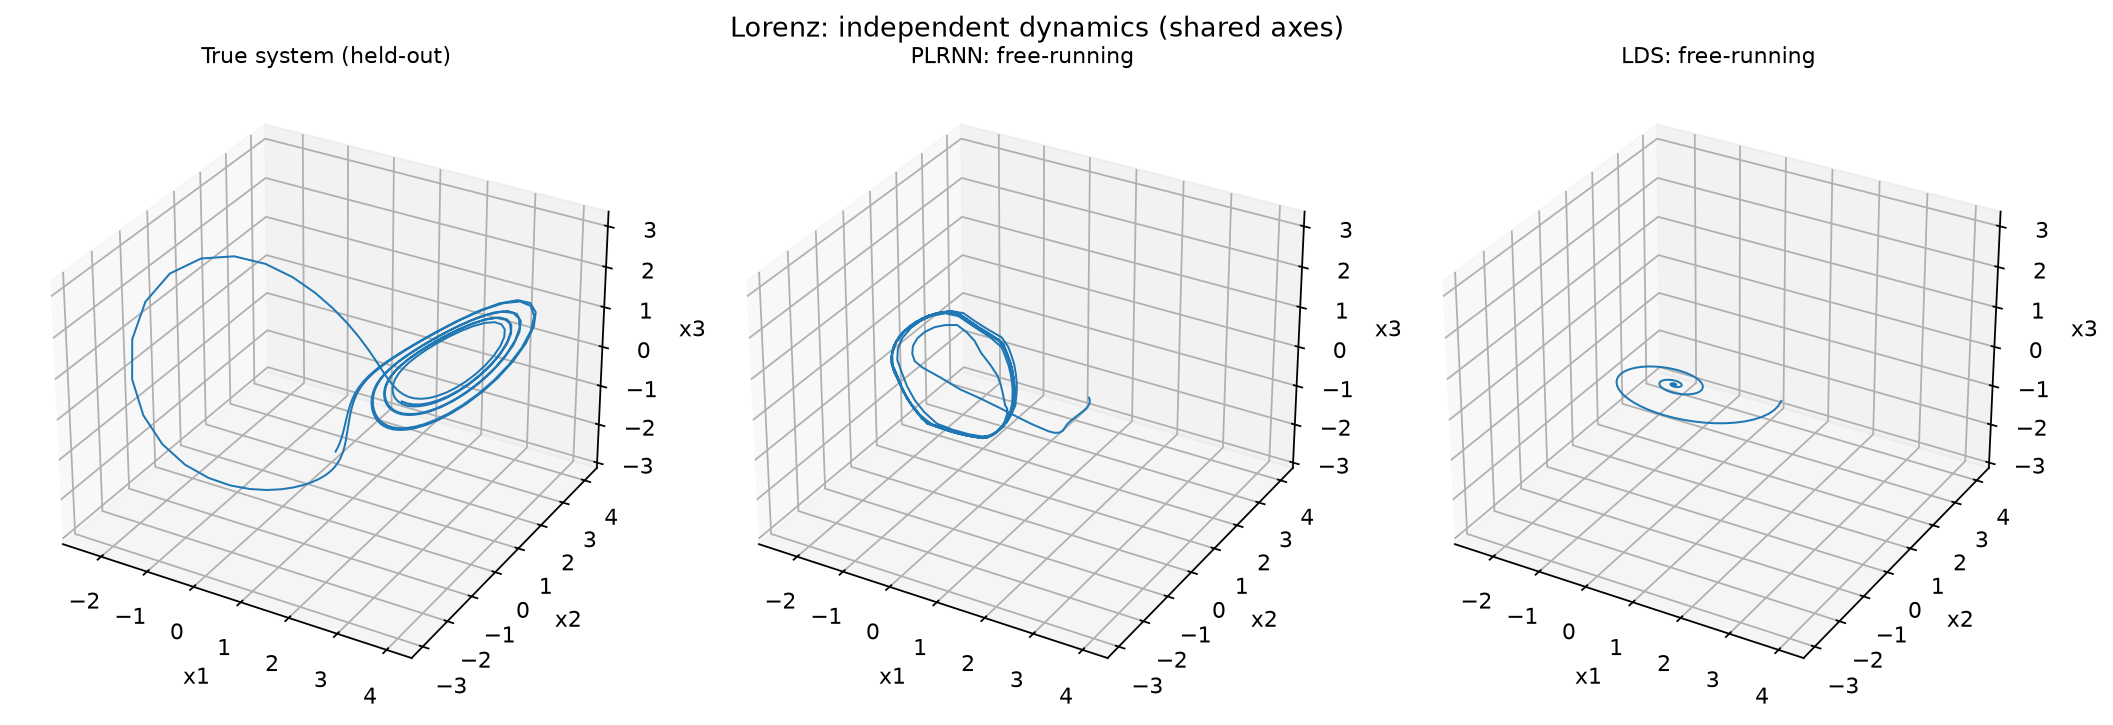

In [5]:
for system, d in records.items():
    print(f'{system}:')
    print('  PLRNN free:', d['plrnn_free'])
    print('  LDS free  :', d['lds_free'])
    path = ROOT / 'results' / 'figures' / f'plrnn_{system}.png'
    if path.exists():
        display(Image(filename=str(path)))

## 7. Inspect training and nonlinear coupling structure

The first plot shows two different errors in **different spaces**: observation reconstruction error and latent transition error. They are not directly comparable to the LDS EM log-likelihood. The second plot shows the learned off-diagonal matrix $W$. A nonzero $W$ indicates nonlinear coupling, but **not** automatic proof of chaos or a correct Lorenz attractor.

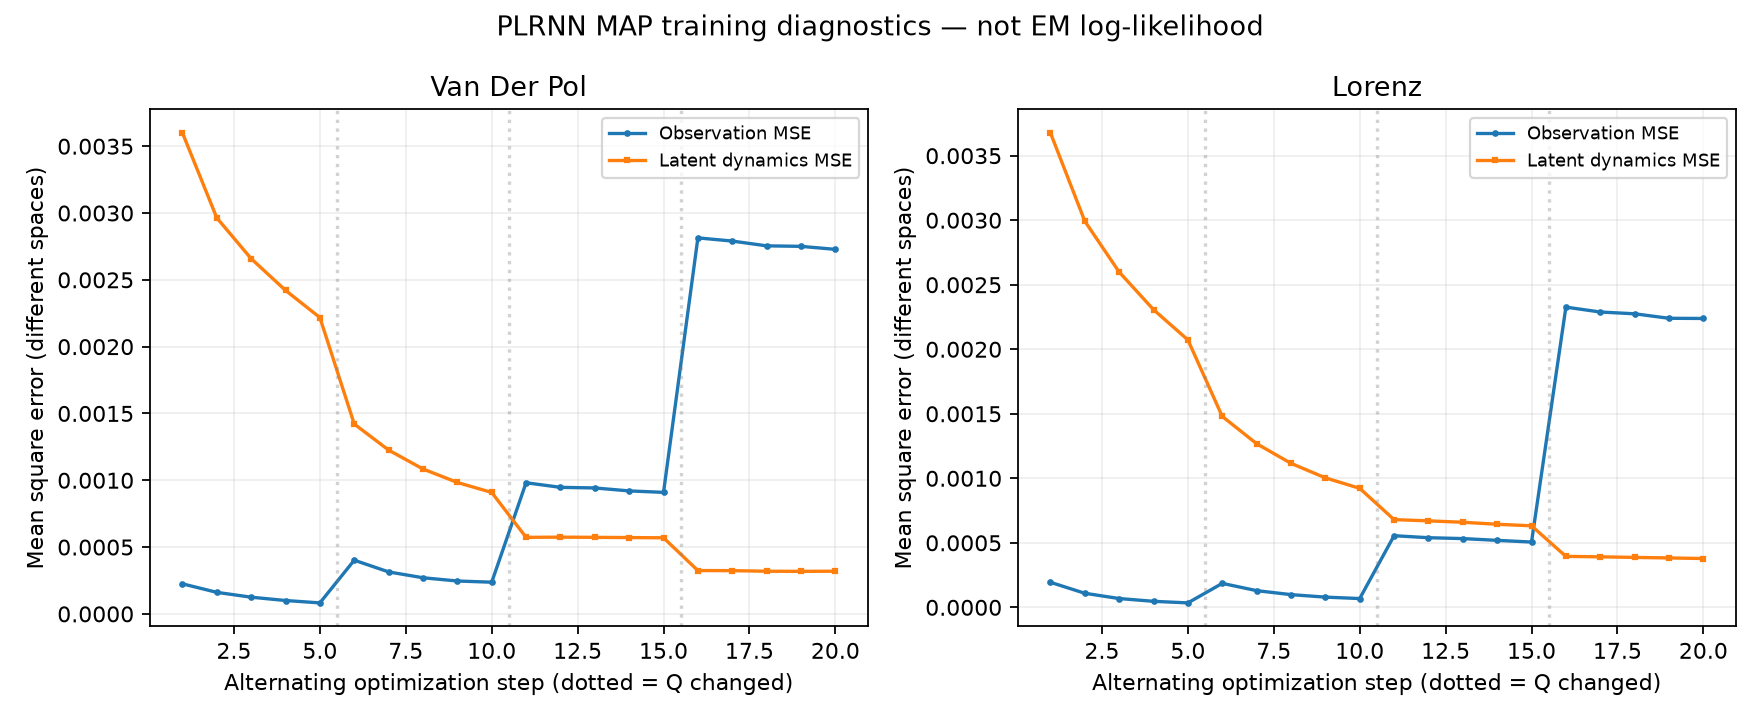

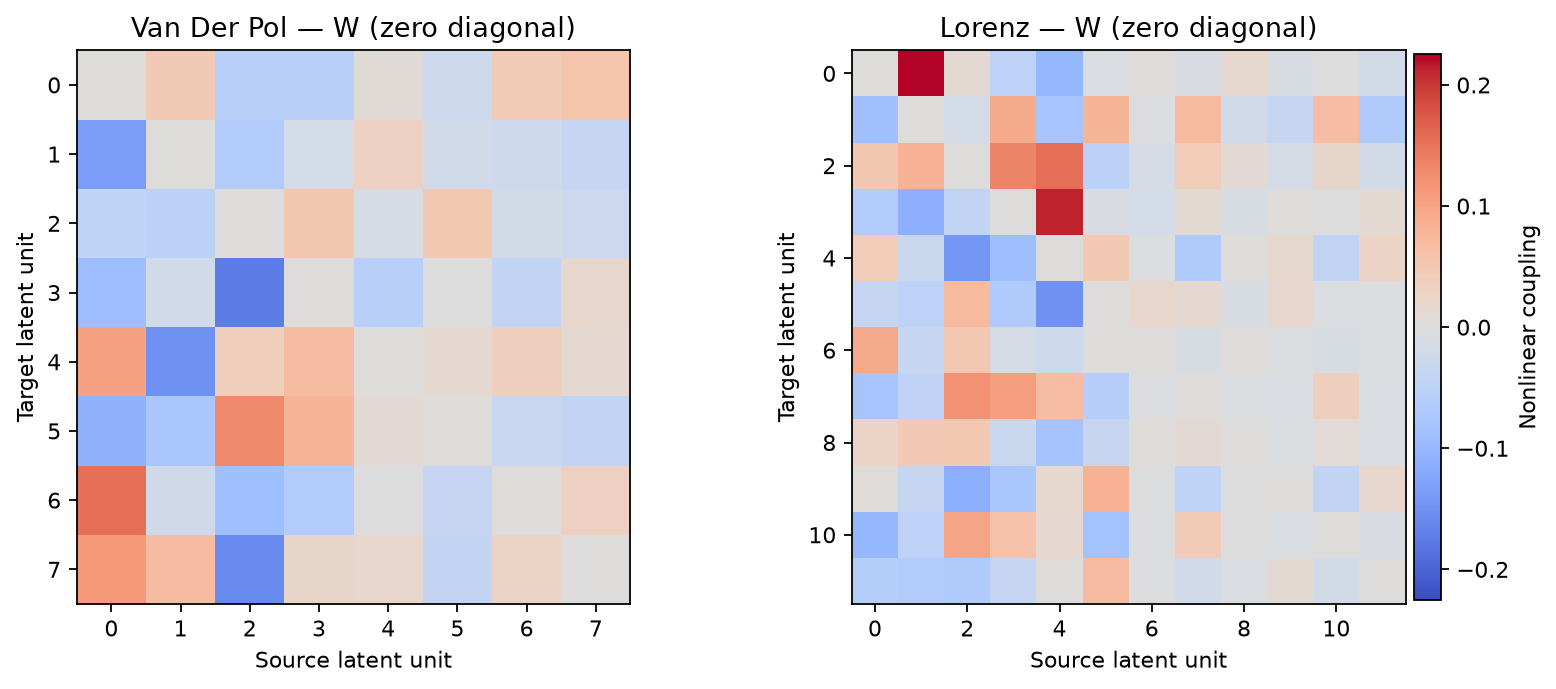

In [6]:
display(Image(filename=str(ROOT/'results'/'figures'/'plrnn_training_curves.png')))
display(Image(filename=str(ROOT/'results'/'figures'/'plrnn_weight_matrices.png')))

## 8. Conclusions and limitations

**Preliminary findings.** In the included training run, the PLRNN obtains lower held-out MSE than the previous LDS for 5-, 10- and 20-step predictions on both systems. An important distinction remains between *forecasting* and *reconstruction of invariant dynamics*: the PLRNN produces sustained oscillations, but the resulting van der Pol shape differs from the true cycle and the Lorenz free trajectory does not yet replicate the complete butterfly attractor.

**Limitations.** Only one seed, 300 test points, different model sizes and inference methods; simplified joint-MAP fitting rather than full Laplace-EM; basic raw histogram KL rather than normalized KL of the paper; no rigorous Lyapunov-exponent measurement or fMRI HRF observation model at this stage.

**Next steps.** Run several seeds, compare equal-capacity baselines, improve autonomous attractor recovery, and then optionally introduce the BOLD/HRF observation model and real fMRI time series.